# Wprowadzenie

W tym projekcie pracujemy na danych dotyczących kredytów. Sprawdzimy, czy dany rachunek zalicza się do portfela pracującego, czy do niepracującego. Wyznaczymy ich liczbę oraz odsetek niewykonania zobowiązania w czasie $t$. Określimy klika grup ryzyka i przypisujemi im oczekiwane wartości straty w przypadku niewykonania zobowiązania na przestrzeni kolejnych 12 miesięcy.

## Opis i przygotowanie dostępnych danych
Przyjrzyjmy się najpierw danym. Pracujemy na trzech ramkach danych:
1. df_kredyty,
2. df_dma,
3. df_umorzenia.

Zapoznajmy się z ich strukturą, zaczynając od df_kredyty.

In [743]:
import pandas as pd
import numpy as np

df_kredyty = pd.read_parquet("C:/Users/olako/OneDrive/Pulpit/bankowość/kredyty.parquet")
df_umorzenia = pd.read_parquet("C:/Users/olako/OneDrive/Pulpit/bankowość/umorzenia.parquet")
df_dma = pd.read_parquet("C:/Users/olako/OneDrive/Pulpit/bankowość/DMA.parquet")

df_kredyty.period_dte = pd.to_datetime(df_kredyty.period_dte)
df_dma.period_dte = pd.to_datetime(df_dma.period_dte)

print("Kredyty:")
df_kredyty.info()

Kredyty:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100942 entries, 0 to 100941
Data columns (total 10 columns):
 #   Column          Non-Null Count   Dtype         
---  ------          --------------   -----         
 0   id_kredytu      100942 non-null  int64         
 1   period_dte      100942 non-null  datetime64[ns]
 2   start_bal_amt   100942 non-null  float64       
 3   start_dte       100942 non-null  object        
 4   bal_amt         100942 non-null  float64       
 5   kwota_przeterm  100942 non-null  float64       
 6   dpd             100942 non-null  int64         
 7   fl_windykacji   100942 non-null  int64         
 8   fl_smierc       100942 non-null  int64         
 9   ttm             100942 non-null  int64         
dtypes: datetime64[ns](1), float64(3), int64(5), object(1)
memory usage: 7.7+ MB


Dane z  kolumn df_kredyty oznaczają kolejno:
- Id_kredytu – identyfikator kredytu 
- Period_dte – data 
- Start_bal_amt – początkowa kwota kredytu 
- Start_dte – data uruchomienia kredytu 
- Bal_amt – pozostała kwota do spłaty 
- Kwota_przeterm – kwota przeterminowana 
- Dpd  - liczba dni z jakimkolwiek przeterminowaniem 
- Fl_windykacji – oznaczenie rachunków windykowanych 
- Fl_smierc- oznaczenie śmierci kredytobiorców 
- TTM – liczba lat do końca kredytu (czas do zapadalności) 

In [744]:
print("\nDMA:")
df_dma.info()


DMA:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3147928 entries, 0 to 3147927
Data columns (total 3 columns):
 #   Column      Dtype         
---  ------      -----         
 0   id_kredytu  int64         
 1   period_dte  datetime64[ns]
 2   dma         int64         
dtypes: datetime64[ns](1), int64(2)
memory usage: 72.1 MB


Znaczenie kolumn w df_dma: 
- Id_kredytu – identyfikator kredytu 
- Period_dte – data 
- DMA – dni z przeterminowaniem > 400 PLN i >1% wartości ekspozycji 


In [745]:
print("\nUmorzenia:")
df_umorzenia.info()


Umorzenia:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1106 entries, 0 to 1105
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   id_kredytu  1106 non-null   int64  
 1   period_id   1106 non-null   int64  
 2   umorzenie   1106 non-null   float64
dtypes: float64(1), int64(2)
memory usage: 26.1 KB


Dane w kolejnych kolumnach df_umorzenia:
- Id_kredytu 
- Period_id – data w formacie 12*rok+miesiąc 
- Kwota umorzona 

Poniżej przykład użycia df_kredyty do przeglądania historii jednego kredytu (posortowany po dacie).

In [746]:
df_kredyty.loc[df_kredyty.id_kredytu == 102409,:].sort_values('period_dte')

,id_kredytu,period_dte,start_bal_amt,start_dte,bal_amt,kwota_przeterm,dpd,fl_windykacji,fl_smierc,ttm
3571,102409,2021-03-31,15289.53,2021-03-01,-15289.53,0.00,0,0,0,9
3581,102409,2021-04-30,15289.53,2021-03-01,-15160.98,0.00,0,0,0,8
3583,102409,2021-05-31,15289.53,2021-03-01,-15040.72,0.00,0,0,0,8
3578,102409,2021-06-30,15289.53,2021-03-01,-14922.72,0.00,0,0,0,8
3576,102409,2021-07-31,15289.53,2021-03-01,-14801.05,0.00,0,0,0,8
3572,102409,2021-08-31,15289.53,2021-03-01,-14681.58,0.00,0,0,0,8
3573,102409,2021-09-30,15289.53,2021-03-01,-14681.58,-189.73,22,0,0,8
3575,102409,2021-10-31,15289.53,2021-03-01,-14681.58,-399.71,53,0,0,8
3580,102409,2021-11-30,15289.53,2021-03-01,-14681.58,-612.42,83,0,0,8
3577,102409,2021-12-31,15289.53,2021-03-01,-14681.58,-830.54,114,0,0,8


Pierwszym krokiem w przygotowaniu danych będzie dodanie dodatkowej kolumny period_id do df_kredyty i df_dma. Wykorzystany w tym celu znany format: 12 * rok + miesiąc.
Format ten ułatwia operowanie datą w wielu funkcjach (np. przy porównaniu i sortowaniu danych, przesuwaniu się w czasie) oraz niweluje problem różnicy w formacie daty z różnych ramek danych.

In [747]:
df_kredyty['period_id'] = 12*df_kredyty.period_dte.dt.year + df_kredyty.period_dte.dt.month
df_dma['period_id'] = 12*df_dma.period_dte.dt.year + df_dma.period_dte.dt.month

Sprawdzamy, że w żadnej z dostępnych ramkach danych nie pojawiają się wartości NaN.

In [748]:
print(df_kredyty.isna().sum())
print()
print(df_umorzenia.isna().sum())
print()
print(df_dma.isna().sum())

id_kredytu        0
period_dte        0
start_bal_amt     0
start_dte         0
bal_amt           0
kwota_przeterm    0
dpd               0
fl_windykacji     0
fl_smierc         0
ttm               0
period_id         0
dtype: int64

id_kredytu    0
period_id     0
umorzenie     0
dtype: int64

id_kredytu    0
period_dte    0
dma           0
period_id     0
dtype: int64


Możemy zatem złączyć ze sobą df_kredyty i df_dma. Nadpisujemy df_kredyty o informacje o DMA. Uprości to dalsze działania na danych.

In [749]:
df_kredyty = pd.merge(left=df_kredyty, right=df_dma[['period_dte','id_kredytu', 'dma']], left_on=['id_kredytu', 'period_dte'], right_on=['id_kredytu', 'period_dte'], how='left')

df_kredyty.head()

,id_kredytu,period_dte,start_bal_amt,start_dte,bal_amt,kwota_przeterm,dpd,fl_windykacji,fl_smierc,ttm,period_id,dma
0,100003,2022-03-31,58656.19,2022-03-01,-58656.19,0.0,0,0,0,3,24267,0.0
1,100005,2022-03-31,6043.29,2022-03-01,-6043.29,0.0,0,0,0,6,24267,0.0
2,100009,2022-03-31,50543.89,2022-03-01,-50543.89,0.0,0,0,0,3,24267,0.0
3,100015,2022-03-31,60521.05,2022-03-01,-60521.05,0.0,0,0,0,9,24267,0.0
4,100017,2022-03-31,605.00,2022-03-01,-605.00,0.0,0,0,0,1,24267,0.0


Sprawdzamy, czy w całej ramce danych (po złączeniu df_kredyty z df_dma) mamy wartości NaN. Mogły się one pojawić, ze względu na występowanie niektórych obserwacji jedynie w jednej z wyjściowych ramek danych. 

In [750]:
df_kredyty.isna().sum()

id_kredytu         0
period_dte         0
start_bal_amt      0
start_dte          0
bal_amt            0
kwota_przeterm     0
dpd                0
fl_windykacji      0
fl_smierc          0
ttm                0
period_id          0
dma               80
dtype: int64

Pomijamy obserwacje z DMA nieznanym. Nie jesteśmy w stanie określić dla nich typu portfela.

In [751]:
df_kredyty = df_kredyty.loc[df_kredyty.dma.isna() == False, :].copy()

## Oznaczenie defaulta

Oznaczamy portfel niepracujący zgodnie z powyższą definicją niewykonania zobowiązania (default).

Produkt zostaje przeklasyfikowany do portfela niepracującego jeżeli spełniony jest co najmniej jeden z 
poniższych warunków:
* rachunek znajduje się w windykacji, 
* liczba dni z przeterminowaniem >400 PLN i > 1% wartości ekspozycji przekracza 90 dni, 
* nastąpiła śmierć wszystkich kredytobiorców. 

Dodajemy flagę fl_npl oznaczającą portfel niepracujący. Przyjmuje ona wartości 0 (portfel pracujący) i 1 (portfel niepracujący). Wyświetlam dane dla samych kredytów niepracujących.

In [752]:
df_kredyty['fl_npl'] = 0
df_kredyty.loc[df_kredyty.fl_windykacji == 1, 'fl_npl'] = 1
df_kredyty.loc[df_kredyty.fl_smierc == 1, 'fl_npl'] = 1
df_kredyty.loc[df_kredyty.dma > 90, 'fl_npl'] = 1

df_kredyty[df_kredyty['fl_npl'] == 1]

,id_kredytu,period_dte,start_bal_amt,start_dte,bal_amt,kwota_przeterm,dpd,fl_windykacji,fl_smierc,ttm,period_id,dma,fl_npl
3574,102409,2022-02-28,15289.53,2021-03-01,-14681.58,-1274.05,173,0,0,8,24266,112.0,1
3582,102409,2022-03-31,15289.53,2021-03-01,-14681.58,-1499.44,204,0,0,8,24267,143.0,1
3851,102517,2022-03-31,100322.55,2021-02-01,-37873.71,-39623.91,258,1,0,1,24267,259.0,1
3852,102517,2022-02-28,100322.55,2021-02-01,-37873.71,-39623.91,227,1,0,1,24266,228.0,1
3854,102517,2022-01-31,100322.55,2021-02-01,-37873.71,-39623.91,199,1,0,1,24265,200.0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
100622,119503,2015-12-31,17250.00,2007-12-01,-3878.93,-4235.43,998,1,0,-1,24192,423.0,1
100623,119503,2015-11-30,17250.00,2007-12-01,-3878.93,-4235.43,998,1,0,-1,24191,392.0,1
100624,119503,2015-01-31,17250.00,2007-12-01,-3878.93,-4235.43,718,1,0,0,24181,89.0,1
100625,119503,2015-06-30,17250.00,2007-12-01,-3878.93,-4235.43,868,1,0,0,24186,239.0,1


Możemy w prosty sposób sprawdzić, jaka jest suma wszystkich portfeli niepracujących na całym obserwowanym przedziale czasu. Zauważmy, że część rachunków otrzyma status defaulta wielokrotnie. Suma ta uwzględnia każdą taką obserwacje.

In [753]:
print(df_kredyty.period_dte.min())
print(df_kredyty.period_dte.max())
print(df_kredyty.fl_npl.sum())

2015-01-31 00:00:00
2022-03-31 00:00:00
5600


Poniżej widać także porównanie liczby zaobserwowanych portfelów niepracujących do wszystkich portfeli dla danego miesiąca. Możemy zobaczyć, jaki jest ich rząd wielkości w jednym miesiącu.

In [754]:
df_kredyty.groupby('period_dte', dropna=False, as_index=False).agg(DEFAULT_COUNT = ('fl_npl', 'sum'), COUNT = ('id_kredytu', 'count'))

,period_dte,DEFAULT_COUNT,COUNT
0,2015-01-31,55,1000
1,2015-02-28,60,1007
2,2015-03-31,57,1004
3,2015-04-30,60,985
4,2015-05-31,62,969
...,...,...,...
82,2021-11-30,51,1270
83,2021-12-31,51,1249
84,2022-01-31,53,1218
85,2022-02-28,48,1201


## Oznaczenie cure
Rachunek oznaczany jest jako cure (powrót z portfela niepracującego do pracującego), jeśli przestał spełniać definicję defaulta i przez 92 kolejne dni posiadał prawidłową obsługę tj. nie posiadał więcej niż 30 dni przeterminowania (DMA). Czas między ustaniem spełniania przez dany rachunek definicji defaulta a powrotem do portfela pracującego będę nazywać okresem przejściowym.

Aktualna flaga fl_npl oznaczała samo spełnianie definicji defaulta. Ustalimy dodatkowo fl_npl_adj do oznaczenia rachunków, które były defaultami i nie otrzymały jeszcze statusu cure. 

Odczytamy najpierw listę wszystkich kredytów, które kiedykolwiek były defaultem i zapiszemy ją w zmiennej kredyty_default_ever. Przy ustalaniu flagi fl_npl_adj będziemy się iterować jedynie po tych rachunkach. Możemy dzięki tej liście dodatkowo sprawdzić, ile różnych kredytów, było kiedykolwiek defaultem.

In [755]:
kredyty_default_ever = df_kredyty.loc[df_kredyty.fl_npl > 0, "id_kredytu"].drop_duplicates().to_list()
print(len(kredyty_default_ever))

405


Dostępne dane zawierają informację z pojedynczego dnia w danym miesiącu, dlatego przy oznaczeniu fl_npl_adj za 92 dni przyjmiemy 3 kolejne miesiące. Sprawdzamy DMA dopiero w czwartym miesiącu - w poprzednich trzech może przyjmować wartości powyżej 30.

In [756]:
# spisujemy najpierw obserwacje, ktore są defaultem
df_kredyty["fl_npl_adj"] = df_kredyty["fl_npl"].copy()


for kred in kredyty_default_ever:
    df_kred_jeden = df_kredyty.loc[df_kredyty.id_kredytu == kred, :].sort_values("period_id").copy()
    df_kred_jeden["fl_npl_shifted"] = df_kred_jeden["fl_npl"].shift(fill_value = 0)
    # jesli fl_npl = 1 i fl_np_shifted = 0 ---> nowy default
    period_wejscie_default = df_kred_jeden.loc[(df_kred_jeden.fl_npl == 1) & (df_kred_jeden.fl_npl_shifted == 0), "period_id"].to_list()

    # maksymalna obserwowana dana dla danej obserwacji
    max_hist_per = df_kredyty.loc[(df_kredyty.id_kredytu == kred), "period_id"].max()   # maksymalny period_id dla historycznych obserwacji dla każdego (klienta?)
    
    # wykonujemy dla kazdej daty wejscia w default (moze byc kilka razy)
    for i in period_wejscie_default:
        while i <= max_hist_per:
            if df_kredyty.loc[(df_kredyty.id_kredytu == kred) & (df_kredyty.period_id == i), 'fl_npl'].values[0] == 1:
                i += 1
            else:
                j = i

                while (j < i+3) and (j != max_hist_per+1):
                    df_kredyty.loc[(df_kredyty.id_kredytu == kred) & (df_kredyty.period_id == j), 'fl_npl_adj'] = 1
                    j += 1
                
                if j > max_hist_per:
                    i = j + 1
                
                else:
                    #sprawdzamy 4 miesiace
                    #jesli w 4 miesiacu po zakonczeniu def defaulta jest dobra splata oraz dma < 30 = zastan w pl (zakoncz szukanie i przejdz do nastepnego defaulta)
                    if (df_kredyty.loc[(df_kredyty.id_kredytu == kred) & (df_kredyty.period_id == j), 'fl_npl']. values[0] ==  0) & (df_kredyty.loc[(df_kredyty.id_kredytu == kred) & (df_kredyty.period_id == j), 'dma'].values[0] <= 30):
                        #print("Sprawdzam 4 miesiac zamrazarki {} - jest ok mozesz sobie byc juz pracujacy".format(j+1))
                        i = max_hist_per + 1
                    #jesli w 4 miesiacu po zakonczeniu def defaulta model jest
                    else:
                        #print("Nie spelniles w 4 miesiacu {0} warunkow wyjscia z npl - oznaczam cie jako npl i przez kolejne 3 miesiace ...")
                        df_kredyty.loc[(df_kredyty.id_kredytu == kred) & (df_kredyty.period_id == j), 'fl_npl_adj'] = 1
                        i = j + 1

Możemy zobaczyć na przykładzie kredytu o nr. 105267 różnicę między oznaczeniami fl_npl a fl_npl_adj. Na tym przykładzie widać, że rachunek od kwietnia do września 2020 roku spełniał definicję defaulta, ale już po trzech miesiącach okresu przejściowego zmienił status na cure. Natomiast po tym, jak w maju i czerwcu 2021 roku miał status default, po trzech miesiącach z powrotem stał się defaultem i na obserwowanym okresie nie powrócił do statusu portfela pracującego.

In [757]:
df_kredyty.query('id_kredytu == 105267').sort_values('period_dte')

,id_kredytu,period_dte,start_bal_amt,start_dte,bal_amt,kwota_przeterm,dpd,fl_windykacji,fl_smierc,ttm,period_id,dma,fl_npl,fl_npl_adj
14538,105267,2019-10-31,26602.4,2019-10-01,-26602.40,0.00,0,0,0,6,24238,0.0,0,0
14558,105267,2019-11-30,26602.4,2019-10-01,-26602.40,-406.79,0,0,0,5,24239,0.0,0,0
14554,105267,2019-12-31,26602.4,2019-10-01,-26318.78,-401.54,0,0,0,5,24240,0.0,0,0
14541,105267,2020-01-31,26602.4,2019-10-01,-26318.78,-967.31,31,0,0,5,24241,1.0,0,0
14550,105267,2020-02-29,26602.4,2019-10-01,-26318.78,-1533.07,60,0,0,5,24242,30.0,0,0
14542,105267,2020-03-31,26602.4,2019-10-01,-26318.78,-2098.83,91,0,0,5,24243,61.0,0,0
14540,105267,2020-04-30,26602.4,2019-10-01,-25480.59,-759.12,60,0,0,5,24244,91.0,1,1
14556,105267,2020-05-31,26602.4,2019-10-01,-25480.59,-921.78,91,0,0,5,24245,122.0,1,1
14557,105267,2020-06-30,26602.4,2019-10-01,-25480.59,-1072.51,121,0,0,5,24246,152.0,1,1
14543,105267,2020-07-31,26602.4,2019-10-01,-25480.59,-1218.90,152,0,0,5,24247,183.0,1,1


Poniżej porównujemy liczbę defaultów bez uwzględnienia okresu przejściowego z liczbą defaultów wraz z okresem przejściowym.

In [758]:
# default bez okresu przejsciowego
df_kredyty.fl_npl.value_counts(dropna=False)

fl_npl
0    95262
1     5600
Name: count, dtype: int64

In [759]:
# defaulty z okresem przejsciowym
df_kredyty.fl_npl_adj.value_counts(dropna=False)

fl_npl_adj
0    95081
1     5781
Name: count, dtype: int64

## Wyznaczamy wartość ODR

ODR oznacza obserwowany odsetek niewykonania zobowiązania zadany wzorem:

$\text{ODR}_\text{t} = \frac{\text{liczba ekspozycji, które zdefaultują w ciągu roku od momentu t}}{\text{liczba wszystkich ekspozycji w portfelu pracującym w okresie t}}$.

Jest to zatem średnia portfeli niepracujących (oznaczonych przez fl_npl_adj) wśród wszystkich ekspozycji w portfelu pracującym.

W celu obliczenia ODR tworzymy pomocniczą ramkę danych df_kredyty_default, na której będziemy rozpatrywać sytuacje na przestrzeni kolejnych miesięcy.

In [760]:
df_kredyty_default = df_kredyty[['id_kredytu', 'period_id', 'fl_npl_adj']].copy()

In [761]:
for i in range(1, 13):
    # dodajemy kolumne dla kolejnego miesiaca
    df_kredyty_default['period_id_plus_' + str(i)] = df_kredyty_default.period_id + i
    
    # tworzymy tabele pomocnicza
    pom = df_kredyty_default[['period_id', 'id_kredytu', 'fl_npl_adj']].copy()  
    pom = pom.rename(columns = {'fl_npl_adj': 'fl_npl_' + str(i), 'period_id': 'period_id_def_' + str(i)})

    df_kredyty_default = pd.merge(left = df_kredyty_default, 
                          right=pom, 
                          left_on=['id_kredytu', 'period_id_plus_' + str(i)], 
                          right_on=['id_kredytu', 'period_id_def_' + str(i)],                        
                          how='left')


In [762]:
df_kredyty_default.head()

,id_kredytu,period_id,fl_npl_adj,period_id_plus_1,period_id_def_1,fl_npl_1,period_id_plus_2,period_id_def_2,fl_npl_2,period_id_plus_3,...,fl_npl_9,period_id_plus_10,period_id_def_10,fl_npl_10,period_id_plus_11,period_id_def_11,fl_npl_11,period_id_plus_12,period_id_def_12,fl_npl_12
0,100003,24267,0,24268,NaN,NaN,24269,NaN,NaN,24270,...,NaN,24277,NaN,NaN,24278,NaN,NaN,24279,NaN,NaN
1,100005,24267,0,24268,NaN,NaN,24269,NaN,NaN,24270,...,NaN,24277,NaN,NaN,24278,NaN,NaN,24279,NaN,NaN
2,100009,24267,0,24268,NaN,NaN,24269,NaN,NaN,24270,...,NaN,24277,NaN,NaN,24278,NaN,NaN,24279,NaN,NaN
3,100015,24267,0,24268,NaN,NaN,24269,NaN,NaN,24270,...,NaN,24277,NaN,NaN,24278,NaN,NaN,24279,NaN,NaN
4,100017,24267,0,24268,NaN,NaN,24269,NaN,NaN,24270,...,NaN,24277,NaN,NaN,24278,NaN,NaN,24279,NaN,NaN


Tworzymy kolumnę sum_def, która przyjmuje wartości 1, gdy w jednym z kolejnych 12 miesięcy pojawiła się flaga portfela niepracującego, i wartości 0 w przeciwnym wypadku.

In [763]:
df_kredyty_default['sum_def'] = df_kredyty_default[['fl_npl_' + str(i) for i in range(1, 13)]].sum(axis=1).apply(lambda x: 1 if x>0 else 0)

Tworzymy kolumnę flg_default_def_avaliable, w której przechowujemy informację o tym, czy mamy dostępne dane o rodzaju portfela na całym przedziale 12 miesięcy. Przyjmuje ona wartości 1, kiedy mamy pełną historię i 0 w przeciwnym wypadku.

In [764]:
# zliczamy wystapienia NaN na przedziale czasu
df_kredyty_default['flg_default_def_avaliable'] = df_kredyty_default[['fl_npl_' + str(i) for i in range(1, 13)]].isna().sum(axis=1).apply(lambda x: 0 if x != 0 else 1)
df_kredyty_default['flg_default_def_avaliable'].value_counts(dropna=False)

flg_default_def_avaliable
1    53845
0    47017
Name: count, dtype: int64

Kolumna def_12 jest ostateczną informacją, którą chcemy zapamiętać. Przyjmuje ona wartości NaN w przypadku braku potrzebnych danych, 1 - gdy portfel jest niepracujący w jakimś momencie na przedziale kolejnych 12 miesięcy i 0 - gdy pozostanie on pracujący.

In [765]:
df_kredyty_default['def_12m'] = df_kredyty_default.apply(lambda x: x.sum_def if x.flg_default_def_avaliable == 1 else np.NaN, axis=1)
df_kredyty_default.def_12m.value_counts(dropna=False)

def_12m
0.0    48822
NaN    47017
1.0     5023
Name: count, dtype: int64

Te kolumnę chcemy zachować w naszej głównej ramce danych (df_kredyty).

In [766]:
df_kredyty = pd.merge(left=df_kredyty, 
                      right= df_kredyty_default[['id_kredytu', 'period_id', 'def_12m']], 
                      left_on=['id_kredytu', 'period_id'],
                      right_on=['id_kredytu', 'period_id'],
                      how='left')

In [767]:
df_kredyty.def_12m.value_counts(dropna=False)       # liczba defaultow - liczba 1.0

def_12m
0.0    48822
NaN    47017
1.0     5023
Name: count, dtype: int64

Teraz możemy kolejno zliczyć wartość licznika funkcji ODR (liczba ekspozycji, które zdefaultują w ciągu roku od momentu t) i mianownika ODR (liczba wszystkich ekspozycji w portfelu pracującym w okresie t).

In [768]:
df_kredyty.loc[(df_kredyty.fl_npl_adj == 0) & (df_kredyty.def_12m.isna()== False), 'def_12m'].sum() # licznik ODR

3129.0

In [769]:
df_kredyty.loc[(df_kredyty.fl_npl_adj == 0) & (df_kredyty.def_12m.isna()== False), 'def_12m'].count() # mianownik ODR

51941

Możemy także wyznaczyć samą wartość ODR.

In [770]:
df_kredyty.loc[(df_kredyty.fl_npl_adj == 0) & (df_kredyty.def_12m.isna()== False), 'def_12m'].mean() # ODR

0.06024142777382029

## Modelowanie prawdopodobieństwa defaulta (PD) na podstawie dostępnych danych


Zamodelujemy PD (prawdopodobieństwo wystąpienia defaulta) na podstawie dostępnych danych. Zdefiniujemy kilku grup ryzyka i przypiszemy im oczekiwane prawdopodobieństwo wystąpienia zdarzenia default w ciągu kolejnych 12 miesięcy. 

W tym celu stworzymy drzewo decyzyjne, które rozdziela obserwacje na trzy grupy ryzyka w zależności od kwoty pozostałej do spłaty (bal_amt). Dla każdej z nich wyliczamy prawdopodobieństwo defaulta, bazując na danych ze stworzonej kolumny def_12m, która określa pojawienie się defaulta w ciągu 12 miesięcy.

In [771]:
from sklearn import tree

In [772]:
X_model = df_kredyty.loc[(df_kredyty.fl_npl_adj == 0) & (df_kredyty.def_12m.isna()==False), ['bal_amt']].reset_index(drop=True)
Y_model = df_kredyty.loc[(df_kredyty.fl_npl_adj == 0) & (df_kredyty.def_12m.isna()==False), ['def_12m']].reset_index(drop=True)

In [773]:
clf = tree.DecisionTreeRegressor(max_depth=2, min_samples_leaf=0.05)
clf = clf.fit(X=X_model, y=Y_model)

[Text(0.6, 0.8333333333333334, 'node #0\nbal_amt <= -3138.43\nsquared_error = 0.057\nsamples = 51941\nvalue = 0.06'),
 Text(0.4, 0.5, 'node #1\nbal_amt <= -11075.44\nsquared_error = 0.052\nsamples = 47348\nvalue = 0.055'),
 Text(0.5, 0.6666666666666667, 'True  '),
 Text(0.2, 0.16666666666666666, 'node #2\nsquared_error = 0.048\nsamples = 30253\nvalue = 0.051'),
 Text(0.6, 0.16666666666666666, 'node #3\nsquared_error = 0.06\nsamples = 17095\nvalue = 0.064'),
 Text(0.8, 0.5, 'node #4\nsquared_error = 0.098\nsamples = 4593\nvalue = 0.11'),
 Text(0.7, 0.6666666666666667, '  False')]

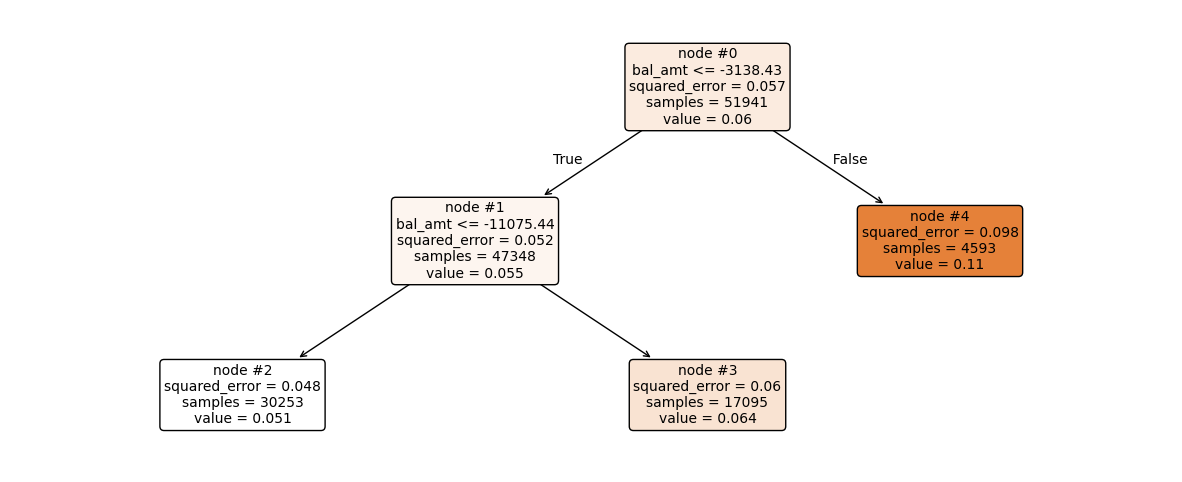

In [774]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15,6))
tree.plot_tree(clf, feature_names=X_model.columns,
               class_names=Y_model.columns, filled=True,
               fontsize=10,
               node_ids=True,
               impurity=True,
               rounded=True)

Powyżej widzimy całe zbudowane drzewo decyzyjne. Możemy z niego odczytać, że kolejne grupy ryzyka (od największej do najmniejszej wartości kwoty pozostałej do spłaty - bal_amt) znajdują się w węzłach 2, 3 i 4. Z węzłów 0 i 1 możemy odczytać warunki graniczne podziału na 3 grupy ryzyka:
* GR 2 (węzeł 2): bal_amt powyżej 11 075.44,
* GR 3 (węzeł 3): bal_amt między 11 075.44 a 3 138.43,
* GR 4 (węzeł 4): bal_amt poniżej 3 138.43.

Możemy także sprawdzić liczbę obserwacji w każdej z określonych grup.

In [775]:
pd.Series(clf.apply(X_model)).value_counts()

2    30253
3    17095
4     4593
Name: count, dtype: int64

Dane ze zbudowanego drzewa wypiszę w tabelce niżej.

In [ ]:
X_model['GR'] = pd.Series(clf.apply(X_model)) # przypisanie numeru liścia do obserwacji (nr grupy ryzyka)
X_model['def_12m'] = Y_model.copy()

X_model.groupby('GR', as_index=False).agg(COUNT = ('def_12m', 'count'), DEFAULT_COUNT = ('def_12m', 'sum'), PD = ('def_12m', 'mean'))

,GR,COUNT,DEFAULT_COUNT,PD
0,2,30253,1528.0,0.050507
1,3,17095,1094.0,0.063995
2,4,4593,507.0,0.110385


Prawdopodobieństwo defaulta w grupie 2 wynosi ok. 5%, w grupie 3 - 6%, a dla grupy 4 - 11%. Zauważmy, że grupa 2 jest dla nas grupą największego ryzyka (kwota zalegania jest w niej największa), a grupa 4 - najmniejszego.

Z danych tych można wysunąć hipotezę, że im mniejsza kwota zostaje do spłaty, tym większe jest prawdopodobieństwo defaulta.